In [2]:
import altair as alt
import pandas as pd

# 1. Cargar el archivo CSV correcto
df = pd.read_csv("/content/Áreas verdes por habitante en zonas urbanas (limpia)(Hoja1).csv")

# 2. Convertir valores con comas decimales a tipo flotante
if df["VALOR DEL INDICADOR EN M2"].dtype == "O":
  df["VALOR DEL INDICADOR EN M2"] = (
      df["VALOR DEL INDICADOR EN M2"].str.replace(",", ".").astype(float)
  )

# 3. Excluir la columna 'CLASIFICACIÓN PNDR' dejando solo COMUNA y el Indicador
df = df[["COMUNA", "VALOR DEL INDICADOR EN M2"]]

# 4. Definir las selecciones para interactividad (Altair 5+)
select = alt.selection_point(name="select", on="click")
highlight = alt.selection_point(
    name="highlight", on="pointerover", empty=False
)

stroke_width = (
    alt.when(select)
    .then(alt.value(2, empty=False))
    .when(highlight)
    .then(alt.value(1))
    .otherwise(alt.value(0))
)

# 5. Construir el gráfico
chart = (
    alt.Chart(df, height=350, width=850)
    .mark_bar(fill="#4C78A8", stroke="black", cursor="pointer")
    .encode(
        x=alt.X("COMUNA:O", title="Comuna", sort=None),
        y=alt.Y(
            "VALOR DEL INDICADOR EN M2:Q", title="Valor del Indicador (m²)"
        ),
        fillOpacity=alt.when(select)
        .then(alt.value(1))
        .otherwise(alt.value(0.3)),
        strokeWidth=stroke_width,
        tooltip=["COMUNA", "VALOR DEL INDICADOR EN M2"],
    )
    .configure_scale(bandPaddingInner=0.2)
    .add_params(select, highlight)
)

chart

alt.Chart(...)

In [8]:
import altair as alt
from google.colab import files
import pandas as pd

# 1. Cargar y preparar los datos usando el archivo CSV correcto disponible
df = pd.read_csv('/content/Áreas verdes por habitante en zonas urbanas (limpia)(Hoja1).csv')
if df['VALOR DEL INDICADOR EN M2'].dtype == 'O':
  df['VALOR DEL INDICADOR EN M2'] = (
      df['VALOR DEL INDICADOR EN M2'].str.replace(',', '.').astype(float)
  )
df = df[['COMUNA', 'VALOR DEL INDICADOR EN M2']]

# 2. Crear las selecciones para la interactividad (en versiones modernas de Altair se usa selection_point)
select = alt.selection_point(name='select', on='click')
highlight = alt.selection_point(
    name='highlight', on='pointerover', empty=False
)

# 3. Construir el gráfico
chart = (
    alt.Chart(df, height=350, width=850)
    .mark_bar(fill='#4C78A8', stroke='black', cursor='pointer')
    .encode(
        x=alt.X('COMUNA:O', title='Comuna', sort=None),
        y=alt.Y(
            'VALOR DEL INDICADOR EN M2:Q', title='Valor del Indicador (m²)'
        ),
        tooltip=['COMUNA', 'VALOR DEL INDICADOR EN M2'],
    )
    .add_params(select, highlight)
)

# 4. Guardar como archivo HTML interactivo
chart.save('grafico_interactivo.html')

# 5. Descargar el archivo HTML automáticamente a tu equipo
files.download('grafico_interactivo.html')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

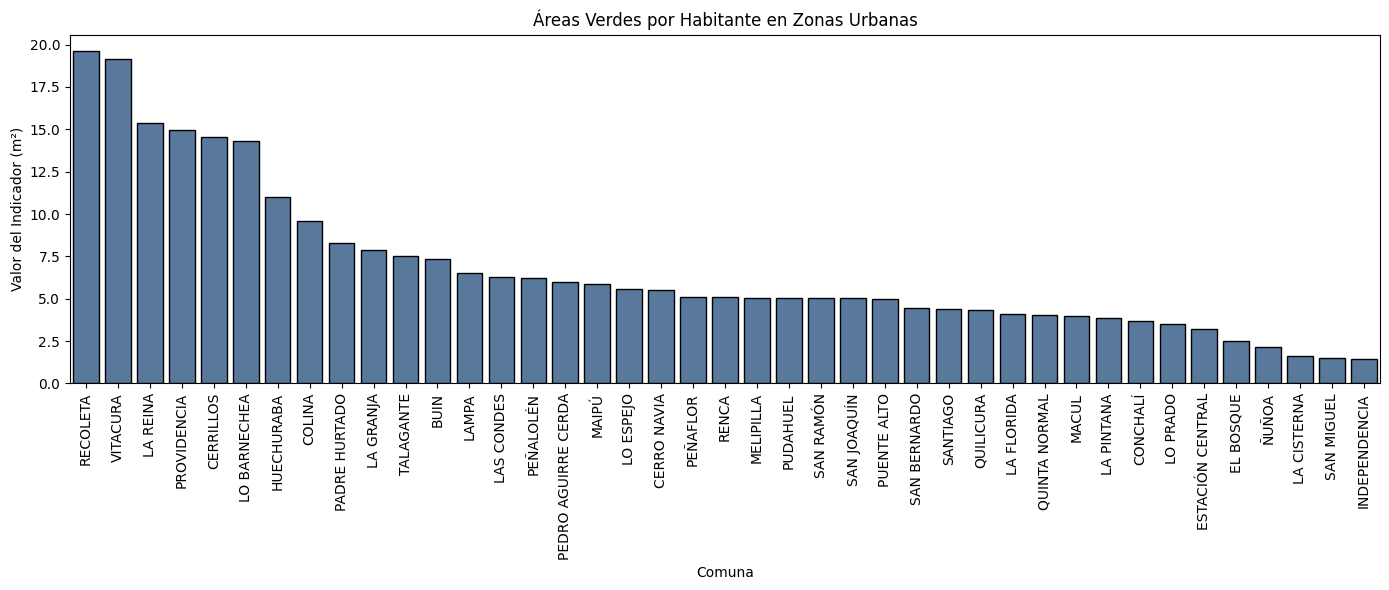

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
from google.colab import files
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Cargar y limpiar datos usando el archivo CSV correcto
df = pd.read_csv('/content/Áreas verdes por habitante en zonas urbanas (limpia)(Hoja1).csv')
if df['VALOR DEL INDICADOR EN M2'].dtype == 'O':
  df['VALOR DEL INDICADOR EN M2'] = (
      df['VALOR DEL INDICADOR EN M2'].str.replace(',', '.').astype(float)
  )

# Crear el gráfico
plt.figure(figsize=(14, 6))
sns.barplot(
    data=df,
    x='COMUNA',
    y='VALOR DEL INDICADOR EN M2',
    color='#4C78A8',
    edgecolor='black',
)

plt.xticks(rotation=90)
plt.title('Áreas Verdes por Habitante en Zonas Urbanas')
plt.xlabel('Comuna')
plt.ylabel('Valor del Indicador (m²)')
plt.tight_layout()

# Guardar como JPG con alta resolución (dpi=300)
plt.savefig('grafico_comunas.jpg', format='jpg', dpi=300)
plt.show()

# Descargar el archivo automáticamente
files.download('grafico_comunas.jpg')